VINEETH JN

AU24UG043

Github : https://github.com/Mirivinee/fashion-mnist-cnn


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
(x_train , y_train ), (x_test,y_test ) = fashion_mnist.load_data()
print("training img ",  x_train.shape , "test img" , x_test.shape , "train y ", y_train.shape , "test y" , y_test.shape)
print( x_train.ndim)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
training img  (60000, 28, 28) test img (10000, 28, 28) train y  (60000,) test y (10000,)
3


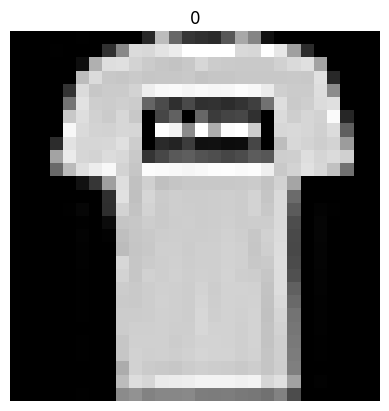

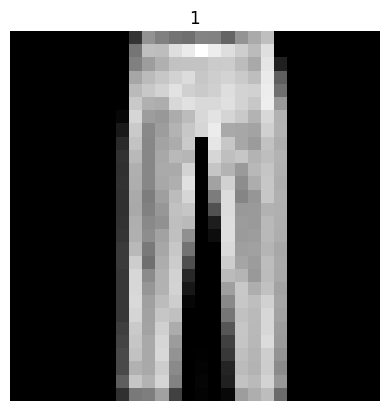

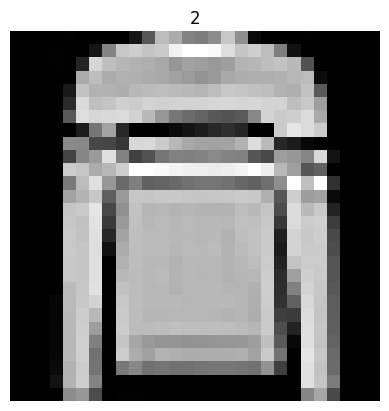

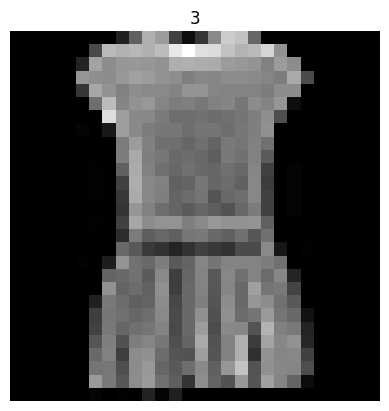

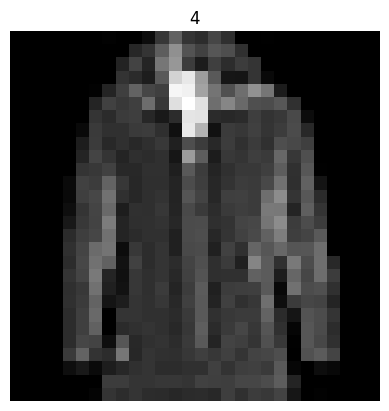

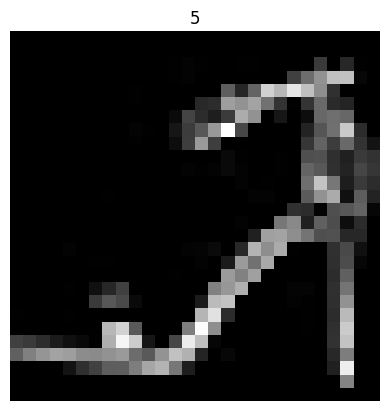

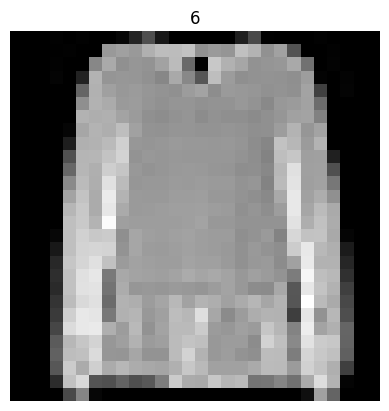

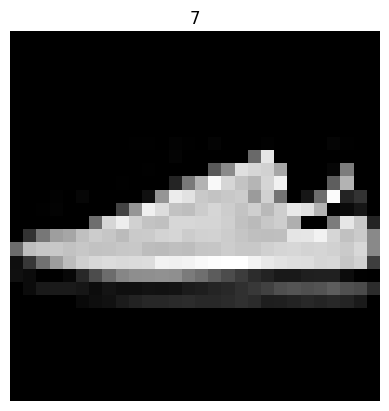

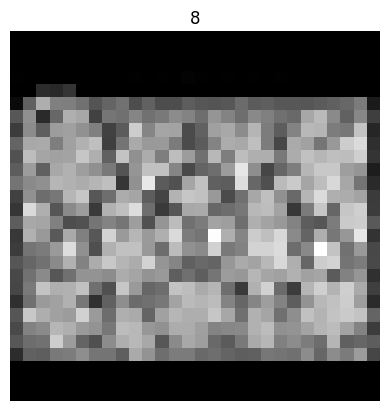

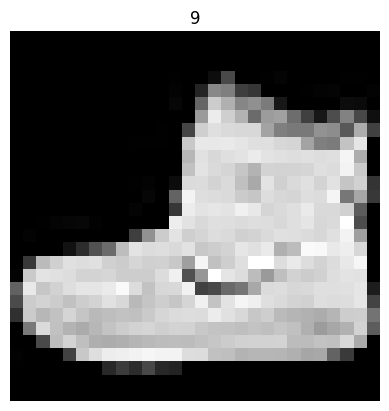

In [2]:
# see how image looks like
# plt.imshow(x_train[1], cmap="gray")
# # plt.imshow(x_train[1], cmap="hot")
# plt.axis("off")
# plt.show()
for i in range(10):
  ii = np.where(y_train == i)[0][0]
  plt.imshow(x_train[ii], cmap="gray")
  plt.title(i)
  plt.axis("off")
  plt.show()



In [3]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

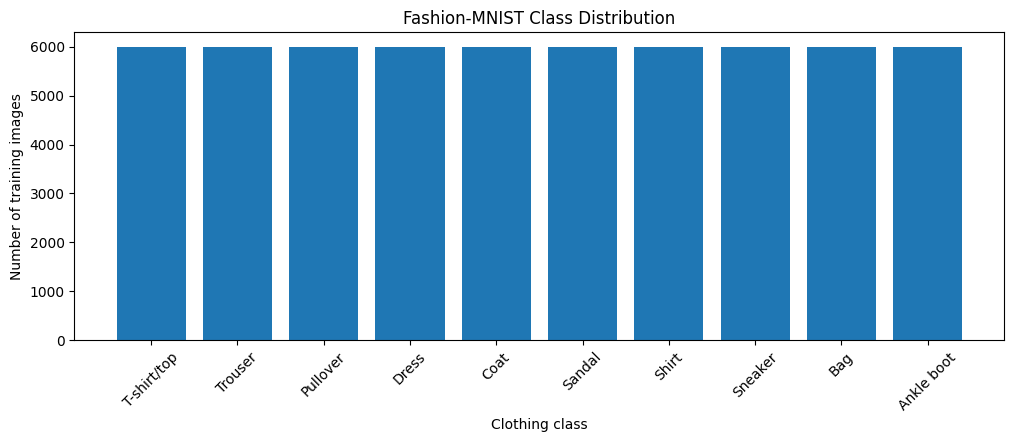

Images per class: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


In [4]:
counts = np.bincount(y_train)
plt.figure(figsize=(12, 4))
plt.bar(class_names, counts)
plt.xlabel("Clothing class")
plt.ylabel("Number of training images")
plt.title("Fashion-MNIST Class Distribution")
plt.xticks(rotation=45)
plt.show()
print("Images per class:", counts)

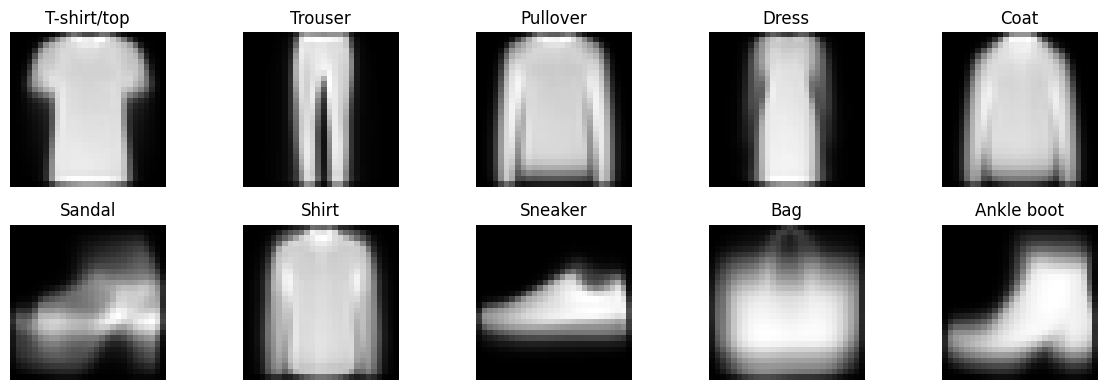

In [5]:
# takeig avg of the pixcels
plt.figure(figsize=(12, 4))
for id in range(10):
    img = x_train[y_train == id]
    avg_img = img.mean(axis=0)

    plt.subplot(2, 5, id + 1)
    plt.imshow(avg_img, cmap="gray")
    plt.title(class_names[id])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# scales the pixel value
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add the channel dimension: (images, height, width, channels)
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())

Training images: (60000, 28, 28, 1)
Test images: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


In [7]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Training: (54000, 28, 28, 1) (54000,)
Validation: (6000, 28, 28, 1) (6000,)
Test: (10000, 28, 28, 1) (10000,)


**OLD MODEL**

In [8]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
X_fashion_train = x_train.reshape(len(x_train), 784)
X_fashion_test = x_test.reshape(len(x_test), 784)
fashion_model = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42
)
fashion_model.fit(X_fashion_train, y_train)
fashion_predictions = fashion_model.predict(X_fashion_test)
fashion_accuracy = accuracy_score(y_test, fashion_predictions)
print("Fashion-MNIST test accuracy:", round(fashion_accuracy, 4))

Fashion-MNIST test accuracy: 0.8697


**Building the CNN**

In [10]:
from tensorflow.keras import models, layers
cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = cnn_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)
test_loss, test_accuracy = cnn_model.evaluate(x_test, y_test)
print("CNN test accuracy:", round(test_accuracy, 4))
print("CNN test loss:", round(test_loss, 4))
print("Baseline test accuracy:", round(fashion_accuracy, 4))
print("CNN test accuracy:", round(test_accuracy, 4))

improvement = test_accuracy - fashion_accuracy
print("Accuracy improvement:", round(improvement * 100, 2), "percentage points")

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 49s 52ms/step - accuracy: 0.8103 - loss: 0.5301 - val_accuracy: 0.8575 - val_loss: 0.3829
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 51ms/step - accuracy: 0.8752 - loss: 0.3482 - val_accuracy: 0.8603 - val_loss: 0.3766
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 49ms/step - accuracy: 0.8924 - loss: 0.3026 - val_accuracy: 0.8935 - val_loss: 0.2965
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9025 - loss: 0.2703 - val_accuracy: 0.9102 - val_loss: 0.2561
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9109 - loss: 0.2475 - val_accuracy: 0.9095 - val_loss: 0.2520
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9159 - loss: 0.2294 - val_accuracy: 0.9122 - val_loss: 0.2418
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9219 - loss: 0.2112 - val_accuracy: 0.9120 - val_loss: 0.2475
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.9264 - loss: 0.1984 - 

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


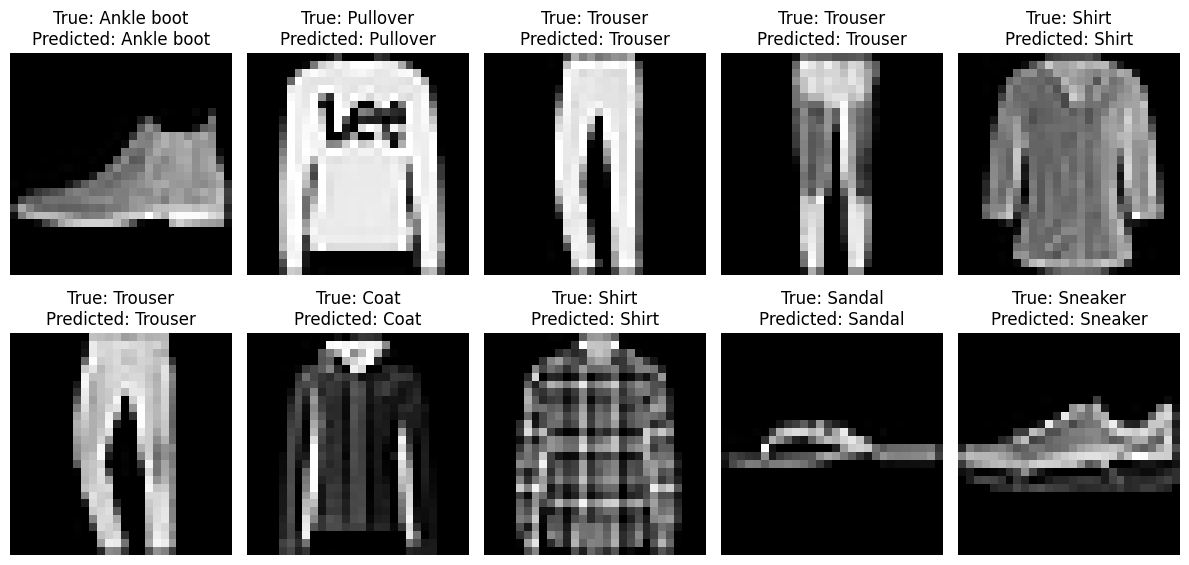

In [12]:
predictions = cnn_model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")

    true_label = class_names[y_test[i]]
    predicted_label = class_names[predicted_labels[i]]

    plt.title(f"True: {true_label}\nPredicted: {predicted_label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

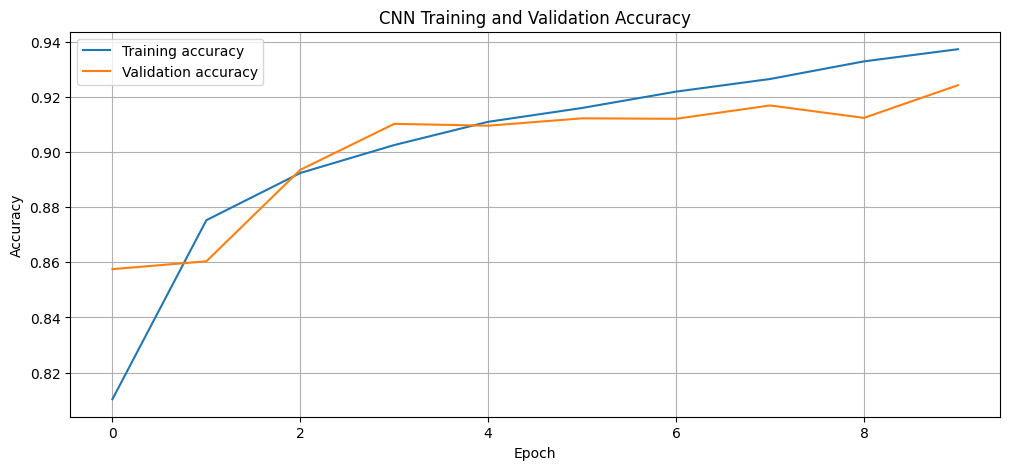

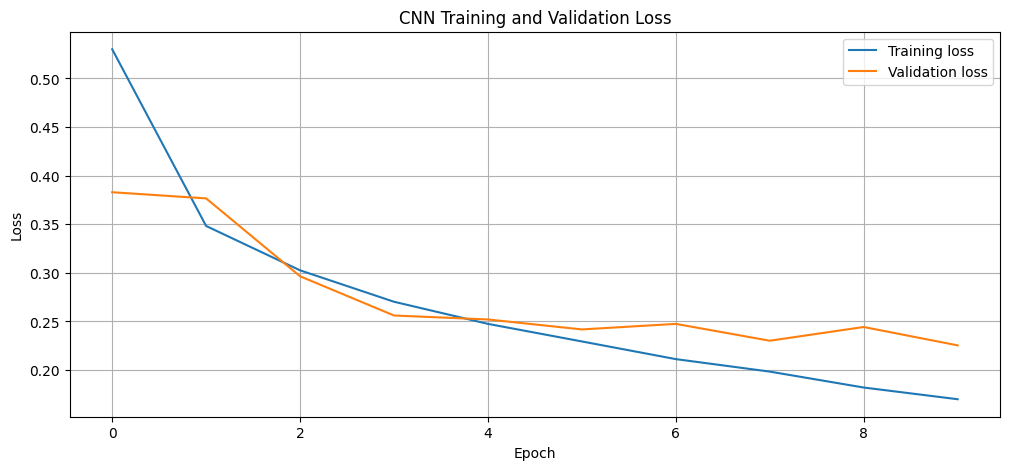

In [13]:
# accuracy curves
plt.figure(figsize=(12, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# loss curves
plt.figure(figsize=(12, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
from sklearn.metrics import classification_report

# Get predicted class labels for the test images
predictions = cnn_model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(
    y_test,
    predicted_labels,
    target_names=class_names
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.87      0.83      0.85      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.86      0.88      0.87      1000
       Dress       0.88      0.94      0.91      1000
        Coat       0.87      0.87      0.87      1000
      Sandal       0.99      0.96      0.97      1000
       Shirt       0.75      0.73      0.74      1000
     Sneaker       0.96      0.96      0.96      1000
         Bag       0.99      0.97      0.98      1000
  Ankle boot       0.95      0.98      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step


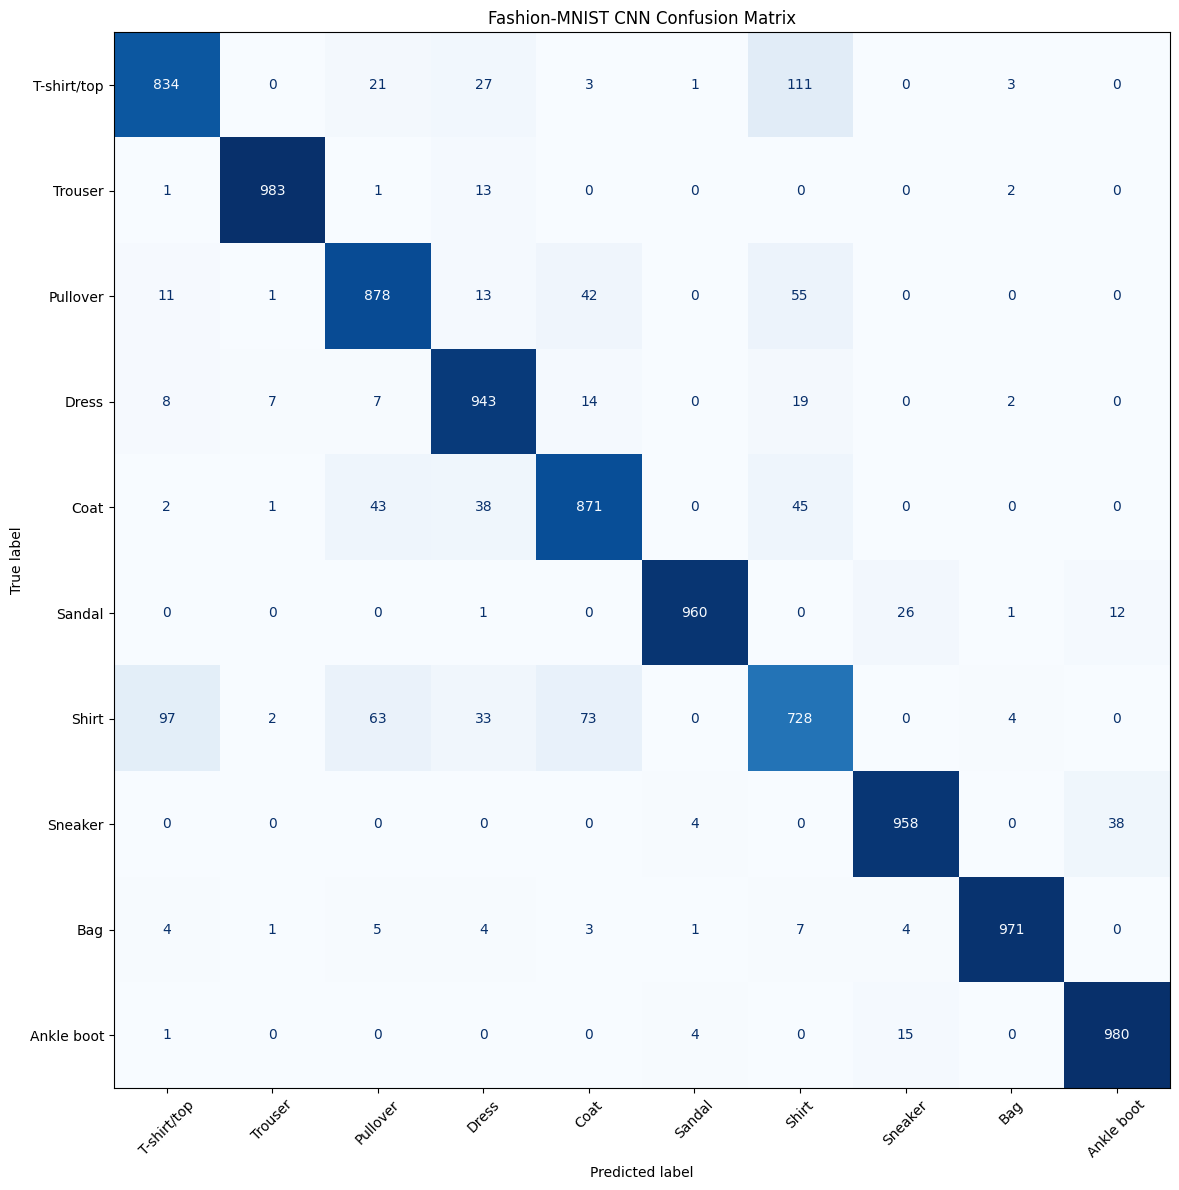

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use predictions from the trained CNN
predictions = cnn_model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, predicted_labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 12))
display.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("Fashion-MNIST CNN Confusion Matrix")
plt.tight_layout()
plt.show()

Total misclassified images: 894


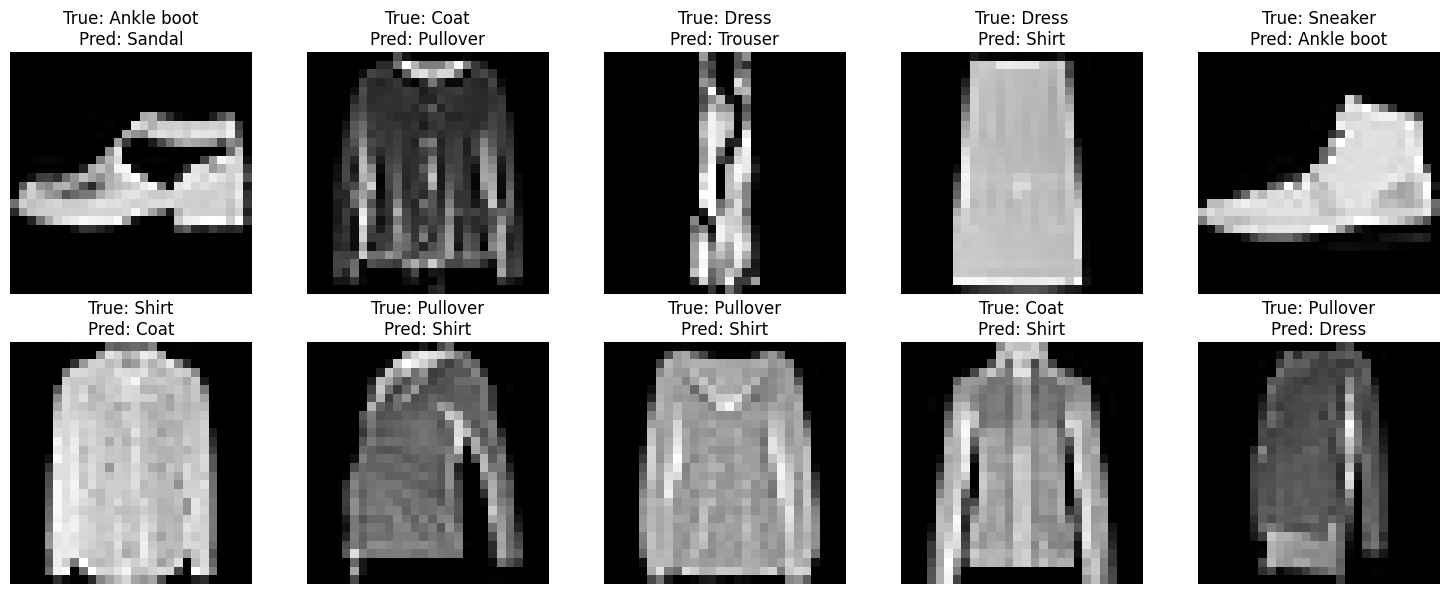

In [18]:
# Find test images the CNN classified incorrectly
wrong_indices = np.where(predicted_labels != y_test)[0]

print("Total misclassified images:", len(wrong_indices))

# Show up to 10 of them
plt.figure(figsize=(15, 6))

for i, idx in enumerate(wrong_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"True: {class_names[y_test[idx]]}\nPred: {class_names[predicted_labels[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# Improvement 1: batch normalization

cnn_bn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

cnn_bn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_bn = cnn_bn.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

bn_loss, bn_accuracy = cnn_bn.evaluate(x_test, y_test, verbose=0)

print(f"Batch Normalization CNN test accuracy: {bn_accuracy:.4f}")

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 90s 102ms/step - accuracy: 0.8229 - loss: 0.5034 - val_accuracy: 0.8870 - val_loss: 0.3088
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 78s 93ms/step - accuracy: 0.8754 - loss: 0.3438 - val_accuracy: 0.8930 - val_loss: 0.2801
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 67s 75ms/step - accuracy: 0.8916 - loss: 0.2978 - val_accuracy: 0.9033 - val_loss: 0.2605
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 112s 111ms/step - accuracy: 0.9014 - loss: 0.2696 - val_accuracy: 0.9075 - val_loss: 0.2515
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 68s 81ms/step - accuracy: 0.9094 - loss: 0.2439 - val_accuracy: 0.8960 - val_loss: 0.2844
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 61s 73ms/step - accuracy: 0.9164 - loss: 0.2249 - val_accuracy: 0.9102 - val_loss: 0.2445
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 63s 74ms/step - accuracy: 0.9207 - loss: 0.2105 - val_accuracy: 0.9147 - val_loss: 0.2327
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 61s 72ms/step - accuracy: 0.9254 - loss: 0.1970

In [20]:
# Improvement 2: add a third convolutional block
cnn_deep = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

cnn_deep.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_deep = cnn_deep.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

deep_loss, deep_accuracy = cnn_deep.evaluate(x_test, y_test, verbose=0)

print(f"Three-convolution-block CNN test accuracy: {deep_accuracy:.4f}")

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 57ms/step - accuracy: 0.7944 - loss: 0.5607 - val_accuracy: 0.8690 - val_loss: 0.3592
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 56ms/step - accuracy: 0.8718 - loss: 0.3526 - val_accuracy: 0.8840 - val_loss: 0.3036
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 57ms/step - accuracy: 0.8917 - loss: 0.2991 - val_accuracy: 0.8977 - val_loss: 0.2750
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 55ms/step - accuracy: 0.9012 - loss: 0.2690 - val_accuracy: 0.9090 - val_loss: 0.2437
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.9114 - loss: 0.2429 - val_accuracy: 0.9145 - val_loss: 0.2303
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.9177 - loss: 0.2224 - val_accuracy: 0.9145 - val_loss: 0.2336
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 57ms/step - accuracy: 0.9239 - loss: 0.2033 - val_accuracy: 0.9165 - val_loss: 0.2313
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 57ms/step - accuracy: 0.9289 - loss: 0.1869 - 

In [24]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Original CNN",
        "CNN + Batch Normalization",
        "CNN + Third Conv Block"
    ],
    "Test Accuracy (%)": [
        91.06,
        round(bn_accuracy * 100, 2),
        round(deep_accuracy * 100, 2)
    ]
})

results

,Model,Test Accuracy (%)
0,Original CNN,91.06
1,CNN + Batch Normalization,91.20
2,CNN + Third Conv Block,90.81


In [28]:
import pandas as pd

original_accuracy = 91.06  # percent, from your original CNN test result

print(f"Original CNN: {original_accuracy:.2f}%")
print(f"CNN + Batch Normalization: {bn_accuracy * 100:.2f}%")
print(f"CNN + Third Conv Block: {deep_accuracy * 100:.2f}%")

results = pd.DataFrame({
    "Model": [
        "Original CNN",
        "CNN + Batch Normalization",
        "CNN + Third Conv Block"
    ],
    "Test Accuracy (%)": [
        original_accuracy,
        round(bn_accuracy * 100, 2),
        round(deep_accuracy * 100, 2)
    ]
})

results

Original CNN: 91.06%
CNN + Batch Normalization: 91.20%
CNN + Third Conv Block: 90.81%


,Model,Test Accuracy (%)
0,Original CNN,91.06
1,CNN + Batch Normalization,91.20
2,CNN + Third Conv Block,90.81


In [29]:
results = pd.DataFrame({
    "Model": [
        "Baseline MLP",
        "Original CNN",
        "CNN + Batch Normalization",
        "CNN + Third Conv Block"
    ],
    "Test Accuracy (%)": [
        86.97,
        91.06,
        91.20,
        90.81
    ]
})

results

,Model,Test Accuracy (%)
0,Baseline MLP,86.97
1,Original CNN,91.06
2,CNN + Batch Normalization,91.20
3,CNN + Third Conv Block,90.81


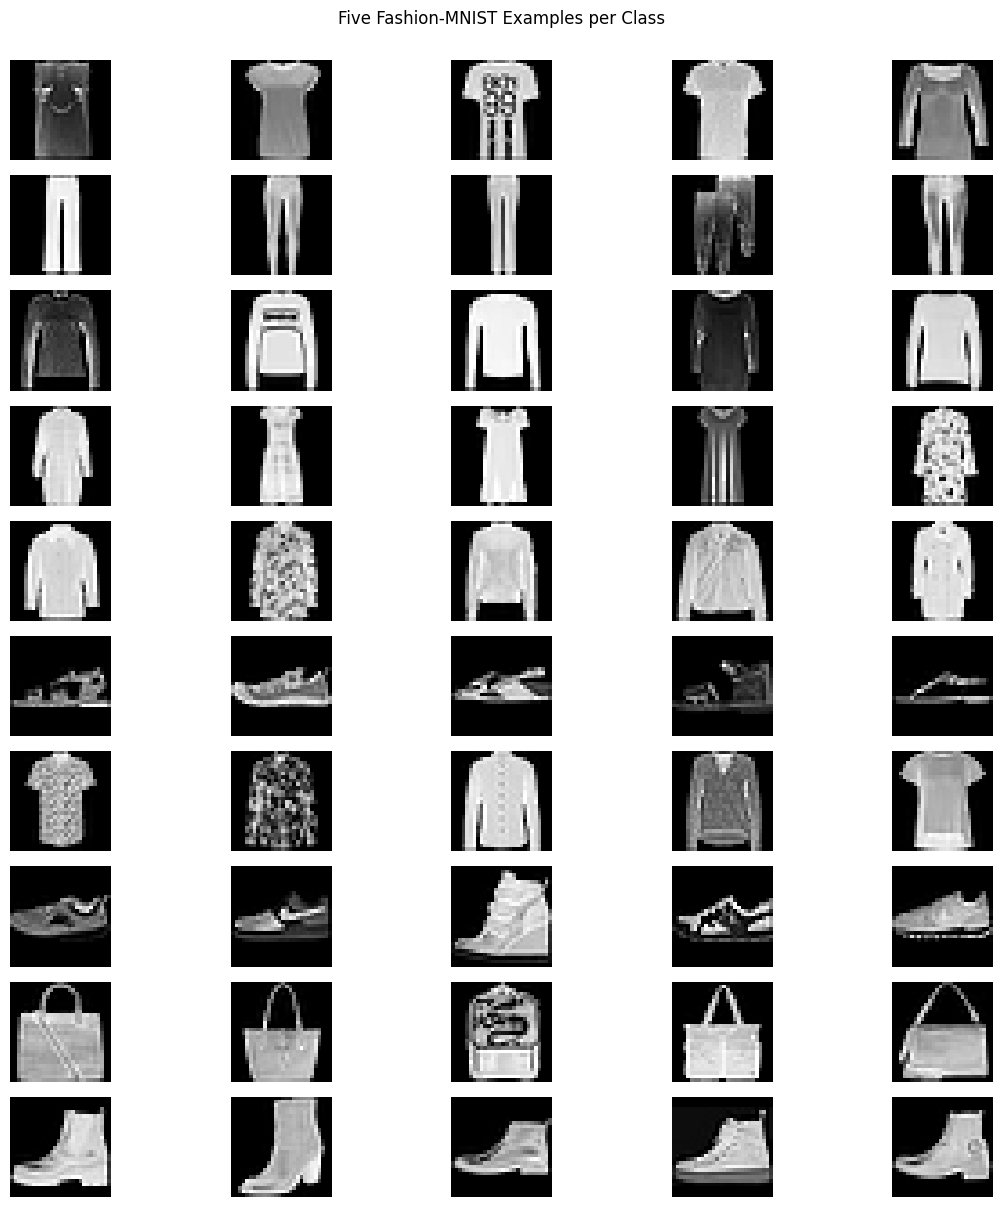

In [30]:
# five examples from each class

plt.figure(figsize=(12, 12))

for class_id in range(10):
    # Get the first five training images belonging to this class
    class_indices = np.where(y_train == class_id)[0][:5]

    for j, idx in enumerate(class_indices):
        plot_position = class_id * 5 + j + 1

        plt.subplot(10, 5, plot_position)
        plt.imshow(x_train[idx].squeeze(), cmap="gray")
        plt.axis("off")

        if j == 0:
            plt.ylabel(class_names[class_id], fontsize=10)

plt.suptitle("Five Fashion-MNIST Examples per Class", y=1.002)
plt.tight_layout()
plt.show()

### 1. Why is Fashion-MNIST harder than MNIST?
Clothes can look similar, and 28×28 images have limited detail. This makes some categories harder to distinguish than handwritten digits.

### 2. Which classes are most confused?
The model often confuses shirts and T-shirts because they look similar at this small size. The confusion matrix can confirm the most confused pair.

### 3. How did the CNN compare with the baseline?
The baseline scored **86.97%**, while the CNN scored **91.06%**. CNNs learn visual patterns like edges and shapes while keeping track of where they appear.

### 4. Which improvement helped most?
Batch normalization helped slightly, reaching **91.20%**. The third convolutional block scored **90.81%**, slightly below the original CNN.

### 5. Is horizontal flipping useful?
It can help with clothing images because flipping usually keeps the clothing category the same. For digits, flipping can change the meaning or appearance, so it is usually not suitable.